## Objetivo del Análisis

El propósito principal de este proyecto es desarrollar y comparar modelos de Machine Learning para predecir la fuga de clientes (churn) utilizando el dataset de Churn Modelling.

### Objetivos Específicos

Objetivo de Negocio: identificar clientes con mayor probabilidad de abandonar el banco, con el fin de facilitar el diseño de estrategias de retención focalizadas y basadas en datos.

Objetivo Técnico y Metodológico: comparar el desempeño de dos enfoques de clasificación diferentes: un modelo lineal, representado por la Regresión Logística, y un modelo no lineal basado en reglas, representado por el Árbol de Decisión.

Criterio de evaluación: analizar el desempeño de ambos modelos mediante Accuracy, Precision, Recall y F1-Score, dando especial importancia al Recall de la clase churn, debido a que el objetivo del análisis es detectar la mayor cantidad posible de clientes que efectivamente abandonarán el banco.

### Configuración del Entorno
Carga de librerías necesarias para la manipulación de datos, visualización, preprocesamiento y modelado analítico.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
  accuracy_score,
  classification_report,
  confusion_matrix,
  f1_score,
  precision_score,
  recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


### Carga de Datos y Inspección Inicial
Importación del dataset crudo (*raw*) y primera revisión de estructura, tipos de datos y dimensiones.

In [2]:
df_raw = pd.read_csv("../Dataset/Churn_Modelling.csv")
df_auditado = df_raw.copy()
df_auditado.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Resultados de la Auditoría Inicial de Datos
Tras la inspección del dataset crudo (*raw*), se destacan los siguientes hallazgos:

* **Integridad de datos:** No se detectan valores faltantes (*nulls*) ni incoherencias evidentes en los registros.
* **Codificación previa:** Las variables `HasCrCard` y `IsActiveMember` ya se encuentran codificadas en formato binario ($0$ y $1$).
* **Variables irrelevantes/Identificadores:** Columnas como `RowNumber`, `CustomerId` y `Surname` son identificadores únicos o datos personales que no aportan valor predictivo y deberán ser eliminadas antes del modelado.
* **Desbalanceo de Clases:** La variable objetivo presenta un desbalance significativo: aproximadamente el 80% de los clientes permanece en el banco, mientras que cerca del 20% abandona.Este desbalance hace que la Accuracy, considerada de manera aislada, pueda resultar insuficiente para evaluar el modelo. 
Por este motivo, además de Accuracy se analizarán Precision, Recall y F1-Score, prestando especial atención al Recall de la clase Fuga (1). 
Asimismo, ambos modelos se entrenarán utilizando class_weight='balanced', de manera que el aprendizaje otorgue mayor peso a la clase minoritaria y se reduzca el riesgo de que el modelo favorezca excesivamente la clase mayoritaria.

In [3]:
df_auditado.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


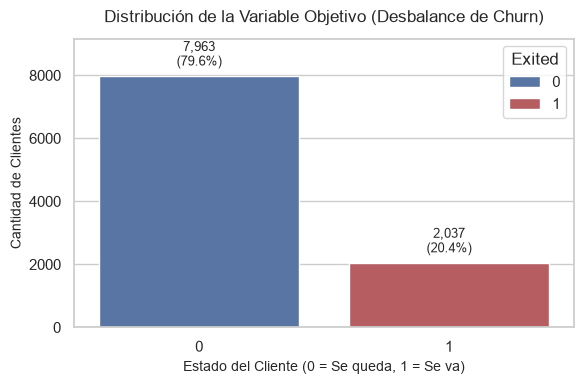

In [4]:
# Configuración estética
sns.set_theme(style='whitegrid')

plt.figure(figsize=(6, 4))

# Solución 1: Quitamos 'hue' para que seaborn dibuje directamente las dos barras limpias por categoría
ax = sns.countplot(
    x='Exited', data=df_auditado, palette=['#4c72b0', '#c44e52'], hue='Exited'
)

plt.title(
    'Distribución de la Variable Objetivo (Desbalance de Churn)',
    fontsize=12,
    pad=12,
)
plt.xlabel('Estado del Cliente (0 = Se queda, 1 = Se va)', fontsize=10)
plt.ylabel('Cantidad de Clientes', fontsize=10)

# Bucle corregido para añadir las etiquetas con el conteo y porcentaje exacto
total = len(df_auditado)
for p in ax.patches:
  height = p.get_height()
  if height > 0:  # Evita errores si algún rectángulo mide 0
    porcentaje = (height / total) * 100
    ax.annotate(
        f'{int(height):,}\n({porcentaje:.1f}%)',
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 5),  # Desplazamiento vertical para la etiqueta
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9,
    )

# Solución 2: Ajustamos el eje Y de forma dinámica basado en la barra más alta + un 15% de espacio extra
plt.ylim(0, df_auditado['Exited'].value_counts().max() * 1.15)

plt.tight_layout()
plt.show()

### Preprocesamiento de Datos (Data Preparation)
En este paso se preparan las variables para la alimentación de los modelos:
1. **Limpieza:** Eliminación de identificadores (`CustomerId`, `RowNumber`, `Surname`).
2. **Transformación Categoría a Numérica:** Aplicación de *One-Hot Encoding* (`drop='first'`) a las variables `Geography` y `Gender`.
3. **Escalado de Características:** Normalización/Estandarización (`StandardScaler`) de variables continuas (`CreditScore`, `Age`, `Tenure`, `Balance`, `NumOfProducts` y `EstimatedSalary`) para modelos sensibles a la escala como Regresión Logística.
4. **División del Dataset:** Separación en conjuntos de entrenamiento (*Train*) y prueba (*Test*) manteniendo la proporción de clases (*stratify*).

In [5]:
# Descartamos metadatos secuenciales o de ID que no aportan al aprendizaje
df_auditado = df_auditado.drop(
    columns=['RowNumber', 'CustomerId', 'Surname'])

In [6]:
target_col = 'Exited'

X = df_auditado.drop(columns=[target_col])
y = df_auditado[target_col]

# Verificación rápida del estado inicial de los datos
print('Dimensiones de X (predictores):', X.shape)
print('Dimensiones de y (objetivo):', y.shape)
print('\nDistribución de clases en y (Desbalance):')
print(y.value_counts(normalize=True) * 100)

Dimensiones de X (predictores): (10000, 10)
Dimensiones de y (objetivo): (10000,)

Distribución de clases en y (Desbalance):
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [7]:
# Se divide temprano para evitar data leakage y, además, utilizar stratify para mantener la proporción de clases.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
numerical_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary',
]
categorical_cols = ['Geography', 'Gender']
binary_cols = ['HasCrCard', 'IsActiveMember']

### A. Escalado de Numéricas (Fit SOLO con train)

In [9]:
scaler = StandardScaler()
scaler.fit(X_train[numerical_cols])

train_num = pd.DataFrame(
    scaler.transform(X_train[numerical_cols]),
    columns=numerical_cols,
    index=X_train.index,
)
test_num = pd.DataFrame(
    scaler.transform(X_test[numerical_cols]),
    columns=numerical_cols,
    index=X_test.index,
)

### B. Codificación de Categóricas con drop='first' (Fit SOLO con train)

In [10]:
encoder = OneHotEncoder(
    sparse_output=False, handle_unknown='ignore', drop='first'
)
encoder.fit(X_train[categorical_cols])

columnas_cat = encoder.get_feature_names_out(categorical_cols)

train_cat = pd.DataFrame(
    encoder.transform(X_train[categorical_cols]),
    columns=columnas_cat,
    index=X_train.index,
)
test_cat = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=columnas_cat,
    index=X_test.index,
)

### C. Ensamblaje Final de los Datasets

In [11]:
X_train_final = pd.concat(
    [train_num, train_cat, X_train[binary_cols]], axis=1
)
X_test_final = pd.concat([test_num, test_cat, X_test[binary_cols]], axis=1)

print('¡Preprocesamiento completado con éxito!')
print('Dimensiones finales de X_train_final:', X_train_final.shape)
print('Dimensiones finales de X_test_final:', X_test_final.shape)

¡Preprocesamiento completado con éxito!
Dimensiones finales de X_train_final: (8000, 11)
Dimensiones finales de X_test_final: (2000, 11)


## Entrenamiento y Evaluación de Modelos

### Modelos a Evaluar:
Regresión Logística — Modelo Lineal
Se utiliza como modelo de referencia (baseline) debido a su simplicidad y capacidad de interpretación. La Regresión Logística modela la probabilidad de pertenecer a la clase churn a partir de una combinación lineal de las variables predictoras.
El modelo utiliza regularización L2, aplicada por defecto por LogisticRegression, y class_weight='balanced' para considerar el desbalance entre clientes que permanecen y clientes que abandonan.

Árbol de Decisión — Modelo No Lineal
Se incorpora un Árbol de Decisión como alternativa al modelo lineal. A diferencia de la Regresión Logística, el árbol permite representar relaciones no lineales mediante reglas y divisiones sucesivas de las variables.
Se establece una profundidad máxima de 4 y un mínimo de 20 observaciones por hoja con el objetivo de limitar la complejidad del árbol y reducir el riesgo de sobreajuste.
De esta manera, la comparación permite evaluar si un modelo capaz de representar relaciones no lineales ofrece ventajas frente al modelo lineal de referencia.

### A. Regresión Logística (Modelo Lineal con penalización y balance de clases)

In [12]:
modelo_logistico = LogisticRegression(
    random_state=42, max_iter=1000, class_weight='balanced'
)

### B. Árbol de Decisión (Modelo Basado en Reglas - Fijamos un max_depth opcional para evitar el sobreajuste inicial (*overfitting*)) 

In [13]:
modelo_arbol = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced',
    max_depth=4,  # Limitamos la profundidad para controlar la complejidad
    min_samples_leaf=20,  # Mínimo de muestras por hoja para estabilizar reglas
)

## Entrenamiento (Fitting) con el set de Train

In [14]:
print('Entrenando Regresión Logística...')
modelo_logistico.fit(X_train_final, y_train)

print('Entrenando Árbol de Decisión...')
modelo_arbol.fit(X_train_final, y_train)

print(
    '\n¡Modelos entrenados exitosamente y listos para la fase de'
    ' evaluación/predicción!'
)

Entrenando Regresión Logística...
Entrenando Árbol de Decisión...

¡Modelos entrenados exitosamente y listos para la fase de evaluación/predicción!


## Generación de Predicciones

In [15]:
# Predicciones de clase (0 o 1)
y_pred_log = modelo_logistico.predict(X_test_final)
y_pred_arbol = modelo_arbol.predict(X_test_final)

## Cálculo de Matriz de Confusion

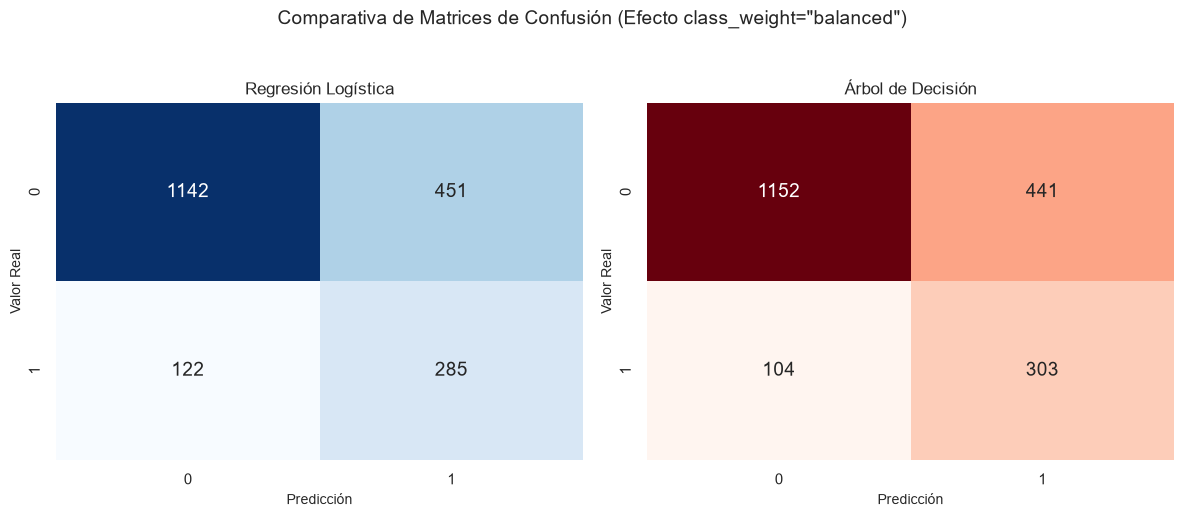

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz 1: Regresión Logística
cm_log = confusion_matrix(y_test, y_pred_log)
sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    ax=axes[0],
    annot_kws={'size': 14},
)
axes[0].set_title('Regresión Logística', fontsize=12)
axes[0].set_xlabel('Predicción', fontsize=10)
axes[0].set_ylabel('Valor Real', fontsize=10)

# Matriz 2: Árbol de Decisión
cm_arbol = confusion_matrix(y_test, y_pred_arbol)
sns.heatmap(
    cm_arbol,
    annot=True,
    fmt='d',
    cmap='Reds',
    cbar=False,
    ax=axes[1],
    annot_kws={'size': 14},
)
axes[1].set_title('Árbol de Decisión', fontsize=12)
axes[1].set_xlabel('Predicción', fontsize=10)
axes[1].set_ylabel('Valor Real', fontsize=10)

plt.suptitle(
    'Comparativa de Matrices de Confusión (Efecto class_weight="balanced")',
    fontsize=14,
    y=1.03,
)
plt.tight_layout()
plt.show()

## Criterios de Evaluación

Para comparar los modelos se utilizan cuatro métricas:

Accuracy: proporción total de predicciones correctas.

Precision (Churn): de los clientes identificados como potenciales casos de fuga, qué proporción efectivamente abandonó.

Recall (Churn): de todos los clientes que efectivamente abandonaron, qué proporción fue detectada por el modelo.

F1-Score (Churn): combina Precision y Recall en una única medida, permitiendo evaluar el equilibrio entre ambas.

En este problema, el Recall de la clase Churn es especialmente relevante. Desde el punto de vista del negocio, un falso negativo representa un cliente que finalmente abandona pero que el modelo no logró identificar, perdiéndose una potencial oportunidad de retención.

Por este motivo, la selección del modelo no se realizará únicamente en función de Accuracy y Recall, sino considerando especialmente su capacidad para detectar clientes que efectivamente abandonan.

In [17]:
modelos = [
    ('Regresión Logística', y_pred_log),
    ('Árbol de Decisión', y_pred_arbol)
]

for nombre, pred in modelos:
    print('=' * 60)
    print(f'REPORTE DE CLASIFICACIÓN: {nombre.upper()}')
    print('=' * 60)
    print(classification_report(y_test, pred, target_names=['Permanencia (0)', 'Fuga (1)'], digits=2))
    print('\n')

REPORTE DE CLASIFICACIÓN: REGRESIÓN LOGÍSTICA
                 precision    recall  f1-score   support

Permanencia (0)       0.90      0.72      0.80      1593
       Fuga (1)       0.39      0.70      0.50       407

       accuracy                           0.71      2000
      macro avg       0.65      0.71      0.65      2000
   weighted avg       0.80      0.71      0.74      2000



REPORTE DE CLASIFICACIÓN: ÁRBOL DE DECISIÓN
                 precision    recall  f1-score   support

Permanencia (0)       0.92      0.72      0.81      1593
       Fuga (1)       0.41      0.74      0.53       407

       accuracy                           0.73      2000
      macro avg       0.66      0.73      0.67      2000
   weighted avg       0.81      0.73      0.75      2000





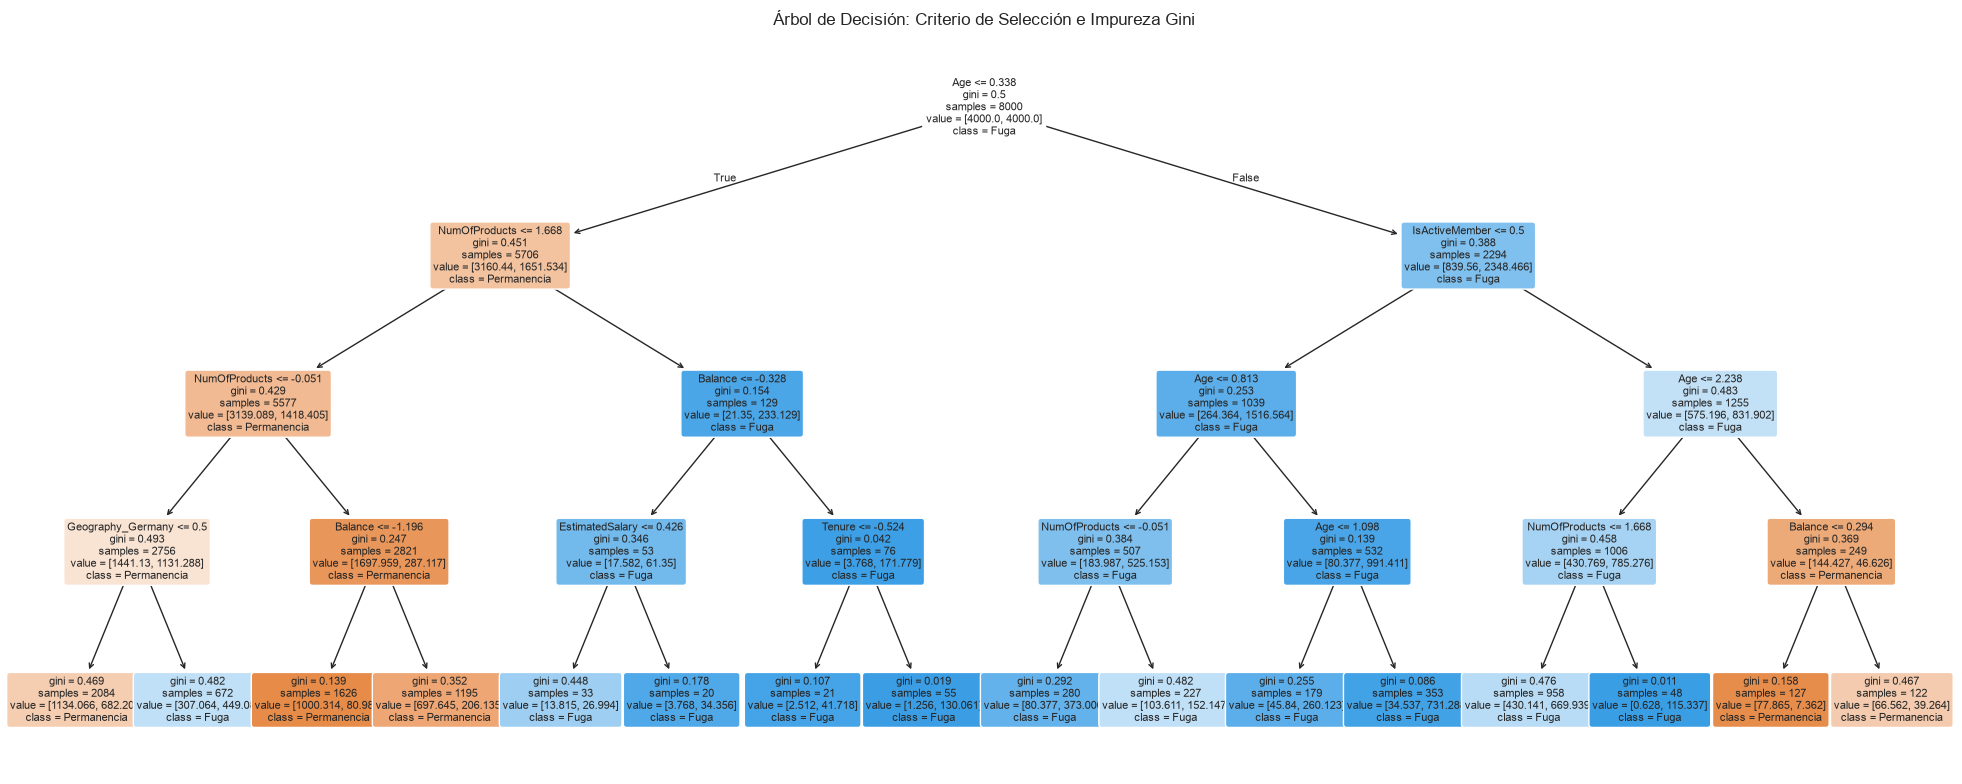

In [18]:
# Colocar después de entrenar el Árbol de Decisión
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(
    modelo_arbol, 
    feature_names=list(X_train_final.columns),
    class_names=['Permanencia', 'Fuga'],
    filled=True, 
    rounded=True, 
    fontsize=8
)
plt.title('Árbol de Decisión: Criterio de Selección e Impureza Gini')
plt.tight_layout()
plt.show()

## Conclusión y Selección del Modelo
A partir de los resultados obtenidos en el conjunto de prueba, el Árbol de Decisión presenta un mejor desempeño que la Regresión Logística en las métricas consideradas, especialmente en el Recall de churn.

La Regresión Logística obtuvo una Accuracy del 71%, un Recall de churn del 70% y un F1-Score del 50%. Por su parte, el Árbol de Decisión alcanzó una Accuracy del 73%, un Recall de churn del 74% y un F1-Score del 53%. Además, la Precision de la clase Fuga también fue ligeramente superior en el Árbol de Decisión (41% frente a 39%).

La diferencia más relevante para el objetivo del proyecto se observa en el Recall de la clase Fuga. La matriz de confusión muestra que, de los 407 clientes que efectivamente abandonaron, la Regresión Logística identifica correctamente 285, mientras que el Árbol de Decisión identifica 303. Esto implica que el árbol logra detectar 18 clientes adicionales que efectivamente abandonaron.

En términos porcentuales, la capacidad de detección pasa aproximadamente del 70% al 74%, lo que representa una mejora de aproximadamente 4 puntos porcentuales en el Recall de churn.

Desde la perspectiva del negocio, esta diferencia resulta relevante porque cada cliente identificado como potencial caso de fuga puede constituir una oportunidad para implementar una acción de retención antes de que se produzca el abandono. Al mismo tiempo, ambos modelos presentan una cantidad considerable de falsos positivos, por lo que las predicciones de churn deberían interpretarse como una herramienta de priorización de clientes y no como una certeza de abandono.

Además, el Árbol de Decisión permite representar las predicciones mediante reglas y umbrales visibles en su estructura, facilitando la comunicación de ciertos patrones de riesgo al equipo de negocio.

Por estos motivos, se selecciona el Árbol de Decisión como modelo final, ya que presenta un mejor desempeño en las métricas evaluadas y, especialmente, una mayor capacidad para detectar clientes que efectivamente abandonan, que constituye el objetivo prioritario del problema planteado.

La elección no implica que la Regresión Logística sea un modelo inadecuado. Por el contrario, funciona como un baseline útil y permite establecer una referencia frente a la cual evaluar el beneficio de utilizar un modelo capaz de capturar relaciones no lineales.